In [1]:
import pandas as pd

df_sephora = pd.read_csv("sephora.csv")
df_ulta = pd.read_csv("ulta.csv")

df = pd.concat([df_sephora, df_ulta], ignore_index=True)

df.head()


,brand,product,url,description,imgSrc,imgAlt,name,specific
0,FENTY BEAUTY by Rihanna,Pro Filt'r Soft Matte Powder Foundation,https://www.sephora.com/product/fenty-beauty-r...,100 for very fair skin with neutral undertones,/productimages/sku/s2413342+sw.jpg,100 0.32 oz/ 9.1 g,NaN,100
1,FENTY BEAUTY by Rihanna,Pro Filt'r Soft Matte Powder Foundation,https://www.sephora.com/product/fenty-beauty-r...,105 for very fair skin with warm yellow undert...,/productimages/sku/s2413359+sw.jpg,105 0.32 oz/ 9.1 g,NaN,105
2,FENTY BEAUTY by Rihanna,Pro Filt'r Soft Matte Powder Foundation,https://www.sephora.com/product/fenty-beauty-r...,110 for very fair skin with cool pink undertones,/productimages/sku/s2413367+sw.jpg,110 0.32 oz/ 9.1 g,NaN,110
3,FENTY BEAUTY by Rihanna,Pro Filt'r Soft Matte Powder Foundation,https://www.sephora.com/product/fenty-beauty-r...,120 for fair skin with neutral undertones,/productimages/sku/s2413375+sw.jpg,120 0.32 oz/ 9.1 g,NaN,120
4,FENTY BEAUTY by Rihanna,Pro Filt'r Soft Matte Powder Foundation,https://www.sephora.com/product/fenty-beauty-r...,130 for fair skin with warm olive undertones,/productimages/sku/s2413383+sw.jpg,130 0.32 oz/ 9.1 g,NaN,130


In [2]:
print(df.info())
print(df.describe())
print(df.columns)

<class 'pandas.DataFrame'>
RangeIndex: 8375 entries, 0 to 8374
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   brand        8375 non-null   str  
 1   product      8375 non-null   str  
 2   url          8375 non-null   str  
 3   description  8375 non-null   str  
 4   imgSrc       8375 non-null   str  
 5   imgAlt       8375 non-null   str  
 6   name         5961 non-null   str  
 7   specific     6100 non-null   str  
dtypes: str(8)
memory usage: 523.6 KB
None
               brand             product  \
count           8375                8375   
unique           113                 357   
top     bareMinerals  Lock-It Foundation   
freq             430                 113   

                                                      url description  \
count                                                8375        8375   
unique                                                385        6683   
top     https://www.se

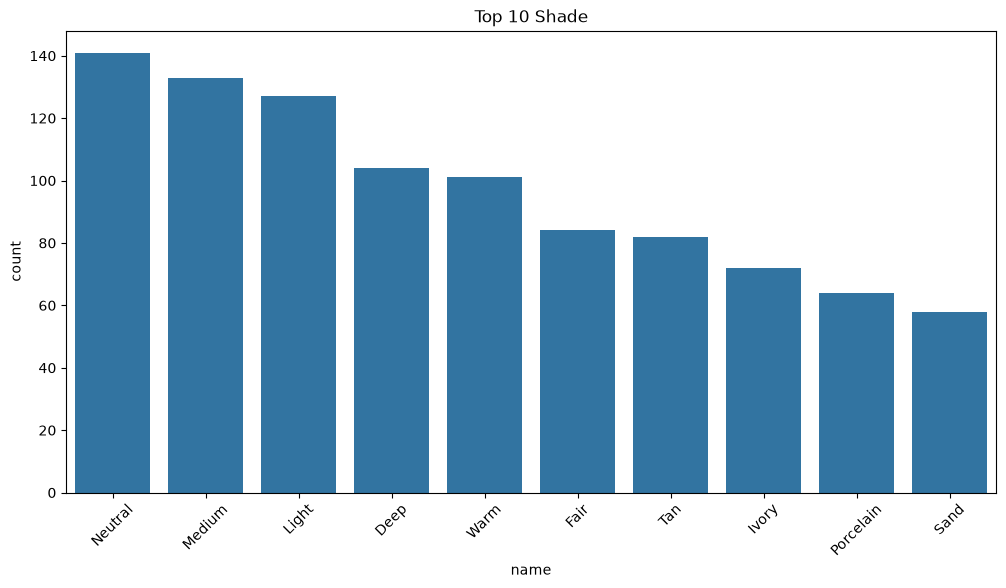

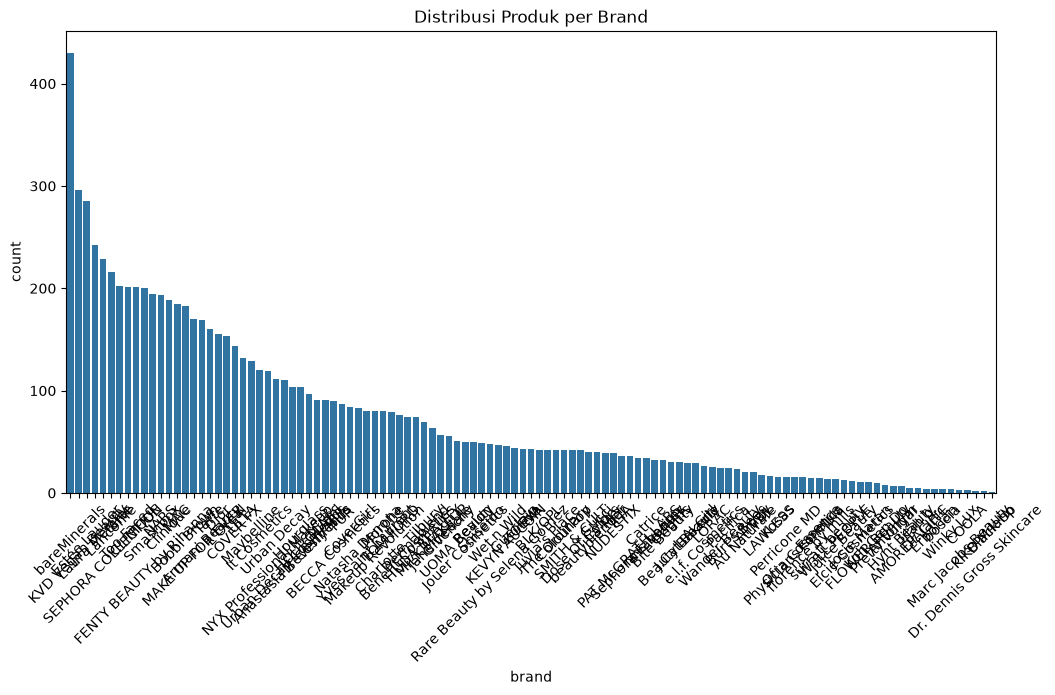

Kolom tersedia: ['brand', 'product', 'url', 'description', 'imgSrc', 'imgAlt', 'name', 'specific']


In [4]:
import matplotlib.pyplot as plt
try:
    import seaborn as sns
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "seaborn"])
    import seaborn as sns

# 1. Distribusi shade (kolom 'name')
plt.figure(figsize=(12,6))
sns.countplot(data=df, x="name", order=df["name"].value_counts().index[:10])
plt.xticks(rotation=45)
plt.title("Top 10 Shade")
plt.show()

# 2. Kalau ada kolom 'brand'
if "brand" in df.columns:
    plt.figure(figsize=(12,6))
    sns.countplot(data=df, x="brand", order=df["brand"].value_counts().index)
    plt.xticks(rotation=45)
    plt.title("Distribusi Produk per Brand")
    plt.show()

# 3. Cek kolom lain yang bisa dianalisis
print("Kolom tersedia:", df.columns.tolist())

In [5]:
from sklearn.preprocessing import LabelEncoder

le_brand = LabelEncoder()
df["Brand_encoded"] = le_brand.fit_transform(df["brand"].astype(str))

df["Skin_Tone"] = df["description"].apply(
    lambda x: "Light" if "ivory" in str(x).lower() else 
              "Medium" if "beige" in str(x).lower() else 
              "Dark"
)

In [6]:
print(df.columns)


Index(['brand', 'product', 'url', 'description', 'imgSrc', 'imgAlt', 'name',
       'specific', 'Brand_encoded', 'Skin_Tone'],
      dtype='str')
